# Privacy attacks on federated learning for brain-tumour MRI: plaintext vs FHE

Three hospitals (clients) train a tumour classifier with Flower federated averaging, once in plaintext and once with
every model update encrypted under CKKS (TenSEAL). Two attacks are then run:

| Attack | Attacker | Target | Expected with FHE |
|---|---|---|---|
| **Gradient inversion (GIA)** | honest-but-curious server | one client's update in round `capture_round` | blocked: the server only has the public key |
| **Model inversion (MIA)** | anyone holding the final model | the final global model | still works: clients decrypt the final model to use it |

**Threat-model choices.** Training uses FedAvg (2 local epochs per round). In `capture_round` clients send a single SGD
step on one image (FedSGD), the setting studied by DLG / iDLG / Geiping et al.; a multi-epoch FedAvg update leaks far less to
this attack. Every client shares one CKKS key pair, so FHE protects against the server, not against a colluding client.

Run from `src/` with the `fed` environment. Full run: about 10 to 15 minutes on a laptop CPU.

In [1]:
import dataclasses
import json
import os
import textwrap

import matplotlib.pyplot as plt
import pandas as pd
import torch

import gia_attack as gia
import mia_attack as mia
from federated import FLConfig, ensure_keys, load_context, run_federated
from models import MRINet
from utils import data_setup

%matplotlib inline
RESULTS = "results"
FIGURES = os.path.join(RESULTS, "figures")
os.makedirs(FIGURES, exist_ok=True)
CLASSES = data_setup.MRI_CLASSES

base = FLConfig(partition="iid", rounds=10, local_epochs=2, capture_round=7, capture_batch_size=1, keys_dir="keys")
plain_cfg = dataclasses.replace(base, he=False, out_dir=os.path.join(RESULTS, "plaintext"))
fhe_cfg = dataclasses.replace(base, he=True, out_dir=os.path.join(RESULTS, "fhe"))

## 1. Federated training: plaintext, then CKKS-encrypted updates

In [2]:
plain_summary = run_federated(plain_cfg)

Federated training: plaintext | 3 clients | iid | 10 rounds


  round  1 | val acc  72.5% | val loss 0.667 | upload 2.02 MB/client | 21s


  round  2 | val acc  83.9% | val loss 0.414 | upload 2.02 MB/client | 10s


  round  3 | val acc  87.9% | val loss 0.340 | upload 2.02 MB/client | 12s


  round  4 | val acc  86.1% | val loss 0.331 | upload 2.02 MB/client | 10s


...

  round  7 | val acc  88.1% | val loss 0.282 | upload 2.02 MB/client | 1s  <- FedSGD capture round


  round  8 | val acc  92.1% | val loss 0.215 | upload 2.02 MB/client | 8s


  round  9 | val acc  93.3% | val loss 0.198 | upload 2.02 MB/client | 8s


  round 10 | val acc  92.5% | val loss 0.198 | upload 2.02 MB/client | 8s


Test accuracy of the final global model: 93.5%


In [3]:
fhe_summary = run_federated(fhe_cfg)

Federated training: FHE (CKKS) | 3 clients | iid | 10 rounds


  round  1 | val acc  72.5% | val loss 0.667 | upload 45.27 MB/client | 20s


  round  2 | val acc  83.7% | val loss 0.422 | upload 45.27 MB/client | 16s


  round  3 | val acc  86.7% | val loss 0.344 | upload 45.27 MB/client | 13s


  round  4 | val acc  86.0% | val loss 0.324 | upload 45.27 MB/client | 14s


...

  round  7 | val acc  87.9% | val loss 0.275 | upload 45.27 MB/client | 3s  <- FedSGD capture round


  round  8 | val acc  92.6% | val loss 0.212 | upload 45.27 MB/client | 9s


  round  9 | val acc  93.9% | val loss 0.198 | upload 45.27 MB/client | 11s


  round 10 | val acc  92.8% | val loss 0.191 | upload 45.27 MB/client | 8s


Test accuracy of the final global model: 93.2%


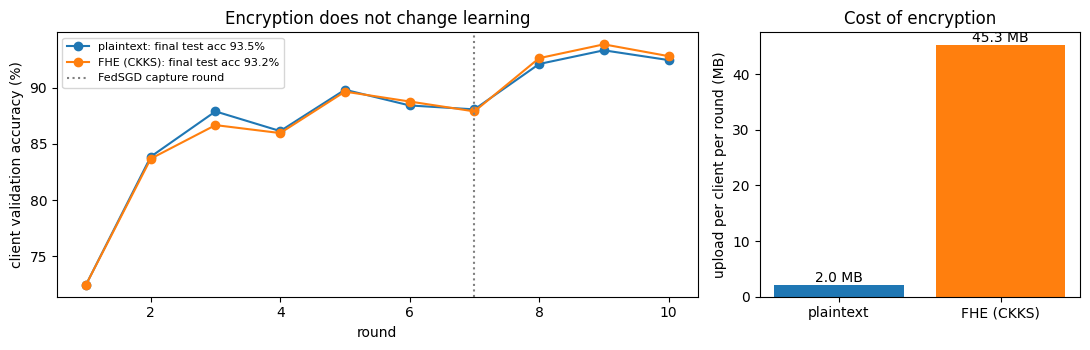

In [4]:
fig, (ax_acc, ax_mb) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2, 1]})
for label, summary in [("plaintext", plain_summary), ("FHE (CKKS)", fhe_summary)]:
    rounds = summary["rounds"]
    ax_acc.plot([r["round"] for r in rounds], [r["val_accuracy"] for r in rounds], marker="o",
                label=f"{label}: final test acc {summary['test_accuracy']:.1f}%")
ax_acc.axvline(base.capture_round, color="gray", ls=":", label="FedSGD capture round")
ax_acc.set(xlabel="round", ylabel="client validation accuracy (%)", title="Encryption does not change learning")
ax_acc.legend(fontsize=8)
uploads = [plain_summary["rounds"][0]["upload_mb_per_client"], fhe_summary["rounds"][0]["upload_mb_per_client"]]
ax_mb.bar(["plaintext", "FHE (CKKS)"], uploads, color=["tab:blue", "tab:orange"])
for i, v in enumerate(uploads):
    ax_mb.text(i, v, f"{v:.1f} MB", ha="center", va="bottom")
ax_mb.set(ylabel="upload per client per round (MB)", title="Cost of encryption")
fig.tight_layout()
fig.savefig(os.path.join(FIGURES, "training.png"), dpi=150, bbox_inches="tight")

## 2. Gradient inversion attack by the server

The server knows the global weights it sent, the update it got back and the step size it asked for, so it recovers
client 0's gradient exactly. It then recovers the label (iDLG), the input of the first fully-connected layer
(Geiping et al., Prop. 1) and finally the image. The client's real image is loaded **only to score** the result.

In [5]:
observation = gia.load_observation(os.path.join(plain_cfg.out_dir, "server_observation.pkl"))
attack = gia.attack_plaintext(observation, MRINet(img_size=base.img_size), cid="0",
                              data_shape=(1, base.img_size, base.img_size))

truth = torch.load(os.path.join(plain_cfg.out_dir, "gia_ground_truth", "client0.pt"))  # scoring only
gia_metrics = gia.evaluate_reconstruction(attack["images"], truth["images"])
gia.save_report({**attack, **gia_metrics, "true_labels": truth["labels"].tolist()},
                os.path.join(plain_cfg.out_dir, "gia_report.json"))
print(f"label recovered: {CLASSES[int(attack['labels'][0])]} (true: {CLASSES[int(truth['labels'][0])]})")
print(f"PSNR {gia_metrics['mean_psnr']:.1f} dB, SSIM {gia_metrics['mean_ssim']:.3f}, {attack['seconds']} s")

    restart 1/2 it     0 | gradient-match loss 7.14251


    restart 1/2 it   500 | gradient-match loss 0.02587


    restart 1/2 it  1000 | gradient-match loss 0.02342


    restart 1/2 it  1500 | gradient-match loss 0.00607


    restart 1/2 it  2000 | gradient-match loss 0.00499


...

    restart 2/2 it  1000 | gradient-match loss 0.01684


    restart 2/2 it  1500 | gradient-match loss 0.00616


    restart 2/2 it  2000 | gradient-match loss 0.00359


    restart 2/2 it  2500 | gradient-match loss 0.00384


    restart 2/2 it  2999 | gradient-match loss 0.00384
label recovered: notumor (true: notumor)
PSNR 26.9 dB, SSIM 0.830, 42.4 s


With FHE the same server holds only ciphertexts and the public context:

In [6]:
fhe_observation = gia.load_observation(os.path.join(fhe_cfg.out_dir, "server_observation.pkl"))
blocked = gia.attempt_on_encrypted(fhe_observation, load_context(ensure_keys(fhe_cfg.keys_dir)[1]), cid="0")
with open(os.path.join(fhe_cfg.out_dir, "gia_report.json"), "w") as f:
    json.dump(blocked, f, indent=2)
blocked

{'client': '0',
 'tensor_type': 'tenseal.ckks',
 'ciphertext_mb': 45.27,
 'status': 'blocked',
 'error': "ValueError: the current context of the tensor doesn't hold a secret_key, please provide one as argument"}

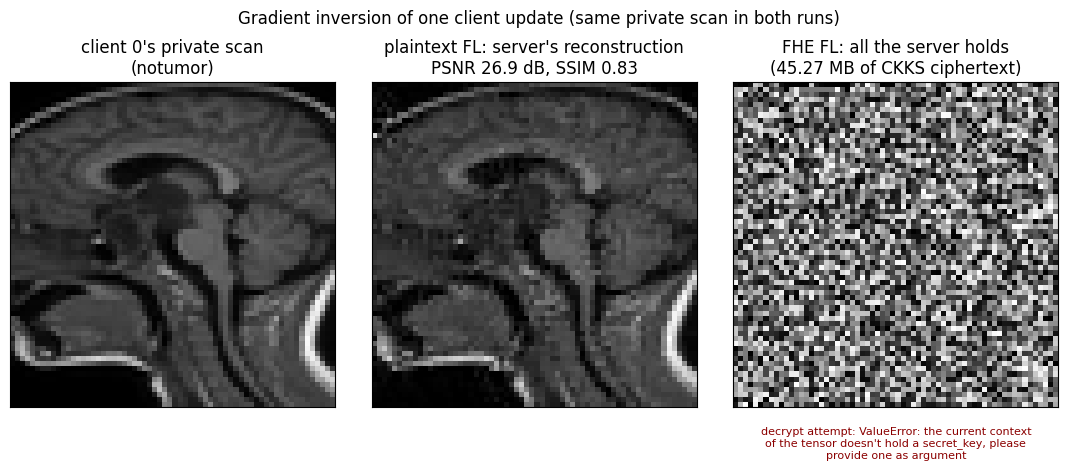

In [7]:
fhe_truth = torch.load(os.path.join(fhe_cfg.out_dir, "gia_ground_truth", "client0.pt"))
fig, axes = plt.subplots(1, 3, figsize=(11, 4.3))
axes[0].imshow(data_setup.to_pixels(truth["images"])[0, 0], cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"client 0's private scan\n({CLASSES[int(truth['labels'][0])]})")
axes[1].imshow(data_setup.to_pixels(attack["images"])[0, 0], cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"plaintext FL: server's reconstruction\nPSNR {gia_metrics['mean_psnr']:.1f} dB, "
                  f"SSIM {gia_metrics['mean_ssim']:.2f}")
axes[2].imshow(gia.ciphertext_preview(fhe_observation, "0"), cmap="gray")
axes[2].set_title(f"FHE FL: all the server holds\n({blocked['ciphertext_mb']} MB of CKKS ciphertext)")
axes[2].text(0.5, -0.06, "\n".join(textwrap.wrap(f"decrypt attempt: {blocked['error']}", 48)),
             transform=axes[2].transAxes, ha="center", va="top", fontsize=8, color="darkred")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
same = torch.equal(truth["images"], fhe_truth["images"])
fig.suptitle("Gradient inversion of one client update" + (" (same private scan in both runs)" if same else ""))
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(os.path.join(FIGURES, "gia.png"), dpi=150, bbox_inches="tight")

## 3. Model inversion attack on the final global model

After training each client decrypts the final model, so FHE no longer protects it. The attacker searches a PCA "brain
image space" fitted on public, unlabelled scans (the held-out Testing split) for images the model assigns to each
class. An independent classifier, trained on the private data with a different architecture, scores the result
(attack accuracy, Zhang et al. 2020). The reconstructions are class prototypes, not specific patients.

In [8]:
arrays = data_setup.load_mri_arrays(base.data_path, base.img_size)
private_x, private_y = data_setup.to_model_input(arrays["x_train"]), torch.as_tensor(arrays["y_train"])
public_x, public_y = data_setup.to_model_input(arrays["x_test"]), torch.as_tensor(arrays["y_test"])

prior = mia.fit_pca_prior(public_x, n_components=100)
evaluator, evaluator_accuracy = mia.train_evaluation_classifier(private_x, private_y, public_x, public_y)
print(f"evaluation classifier test accuracy: {evaluator_accuracy:.1f}%")

    evaluation classifier epoch 1/8: train acc 73.6%


    evaluation classifier epoch 2/8: train acc 83.6%


    evaluation classifier epoch 3/8: train acc 87.0%


    evaluation classifier epoch 4/8: train acc 89.2%


    evaluation classifier epoch 5/8: train acc 91.1%


    evaluation classifier epoch 6/8: train acc 91.5%


    evaluation classifier epoch 7/8: train acc 93.5%


    evaluation classifier epoch 8/8: train acc 94.7%


evaluation classifier test accuracy: 93.6%


plaintext FL


    glioma     target-model conf 0.999 | evaluation classifier says glioma (1.00) | closest private scan: glioma (SSIM 0.51)


    meningioma target-model conf 0.998 | evaluation classifier says notumor (0.31) | closest private scan: notumor (SSIM 0.39)


    notumor    target-model conf 0.999 | evaluation classifier says notumor (0.91) | closest private scan: notumor (SSIM 0.41)


    pituitary  target-model conf 1.000 | evaluation classifier says pituitary (0.89) | closest private scan: notumor (SSIM 0.39)
FHE FL


    glioma     target-model conf 0.999 | evaluation classifier says glioma (1.00) | closest private scan: glioma (SSIM 0.51)


    meningioma target-model conf 0.997 | evaluation classifier says meningioma (0.36) | closest private scan: notumor (SSIM 0.39)


    notumor    target-model conf 0.999 | evaluation classifier says notumor (0.92) | closest private scan: notumor (SSIM 0.41)


    pituitary  target-model conf 1.000 | evaluation classifier says pituitary (0.92) | closest private scan: notumor (SSIM 0.38)


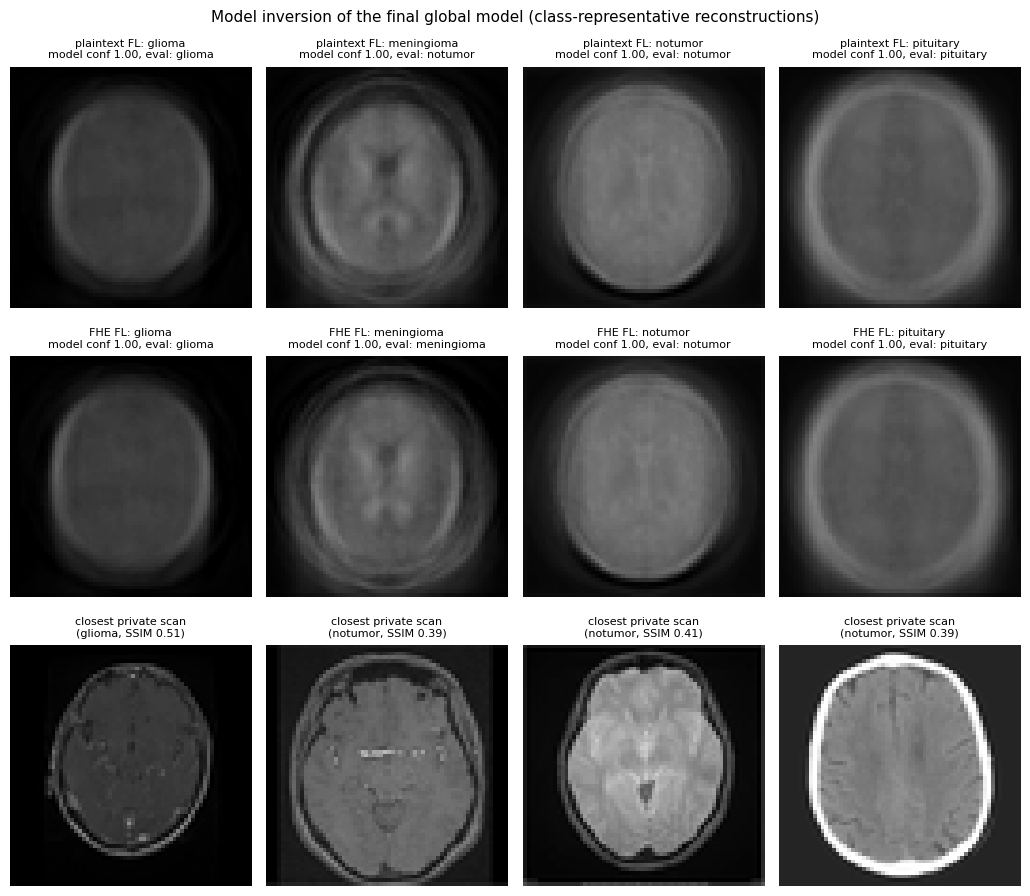

In [9]:
mia_reports = {}
for label, cfg in [("plaintext FL", plain_cfg), ("FHE FL", fhe_cfg)]:
    print(label)
    final_model = MRINet(img_size=base.img_size)
    final_model.load_state_dict(torch.load(os.path.join(cfg.out_dir, "final_model.pt")))  # decrypted by a client
    mia_reports[label] = mia.run_mia(final_model.eval(), prior, evaluator, private_x, private_y, CLASSES)
    mia.save_report(mia_reports[label], os.path.join(cfg.out_dir, "mia_report.json"))
mia.plot_mia(mia_reports, private_x, CLASSES, path=os.path.join(FIGURES, "mia.png"));

## 4. Summary

In [10]:
rows = []
for label, summary, cfg in [("plaintext FL", plain_summary, plain_cfg), ("FHE FL", fhe_summary, fhe_cfg)]:
    he = cfg.he
    rows.append({
        "setting": label,
        "test accuracy (%)": summary["test_accuracy"],
        "upload / client / round (MB)": summary["rounds"][0]["upload_mb_per_client"],
        "training time (s)": summary["training_seconds"],
        "GIA result": "blocked: " + blocked["error"].split(":")[0] if he
                      else f"reconstructed: PSNR {gia_metrics['mean_psnr']:.1f} dB, SSIM {gia_metrics['mean_ssim']:.2f}",
        "MIA attack accuracy": f"{mia_reports[label]['attack_accuracy']:.0%}",
        "MIA mean target confidence": round(sum(r["target_model_confidence"] for r in mia_reports[label]["per_class"]) / 4, 3),
    })
table = pd.DataFrame(rows).set_index("setting")
table.to_json(os.path.join(RESULTS, "summary.json"), orient="index", indent=2)
table

,test accuracy (%),upload / client / round (MB),training time (s),GIA result,MIA attack accuracy,MIA mean target confidence
setting,,,,,,
plaintext FL,93.49,2.02,99.7,"reconstructed: PSNR 26.9 dB, SSIM 0.83",75%,0.999
FHE FL,93.23,45.27,119.8,blocked: ValueError,100%,0.999
